# Stage 3 — Find CA Shifts and Get Object Shifts

## Paths and parameters

In [1]:
# --- paths ----------------------------------------------------------
# From config_steps15.conf, which holds every path for the holotomography scan.
# Edit that file, not this cell.
from holotomocupy.config import parse_args_coded_steps15
_cfg = parse_args_coded_steps15('config_steps15.conf')
WITH_CA = _cfg.path   # processed data for this sample
CORRECTION_FILE = _cfg.correction_file   # ESRF correct3D drift table


In [2]:
import numpy as np
import cupy as cp
import h5py
import matplotlib.pyplot as plt
from holotomocupy.propagation import Propagation
%matplotlib inline

path_out  = WITH_CA + '/'
fname_in  = f'{WITH_CA}/codedHT.h5'       # s2a/s2b output — read+append

# Stage 0's products: in config_step0.conf's nfp/ folder, NOT WITH_CA (ht/) --
# _cfg already resolved these to absolute paths, so use them directly rather
# than rebuilding from WITH_CA.
fname_ca  = _cfg.nfp_file   # Stage 1 NFP HDF5 (provides z1_code)
PATH_CODE = _cfg.code_file  # (8192, 8192) complex64
PATH_PRB  = _cfg.prb_file   # (2048, 2048) complex64

## Load geometry and data from HDF5

In [3]:
with h5py.File(fname_in, 'r') as f:
    energy  = float(f['/exchange/energy'][0])              # [keV]
    det_px  = float(f['/exchange/detector_pixelsize'][0])  # [m]
    fdd     = float(f['/exchange/focusdetectordistance'][0])  # [m]
    z1      = float(f['/exchange/z1'][0])                  # [m]
    ntheta, nz, n = f['/exchange/pdata'].shape
    shifts  = f['/exchange/shifts'][:].astype('float32')   # (ntheta, 2) object drift [px]
    theta_deg = f['/exchange/theta'][:]

with h5py.File(fname_ca, 'r') as f:
    z1_code = float(f['/exchange/z1'][0])   # [m] focus-to-CA distance (negative)

print(f'ntheta={ntheta}, nz={nz}, n={n}')
print(f'z1={z1*1e3:.4f} mm,  z1_code={z1_code*1e3:.4f} mm')
print(f'shifts: {shifts.shape}, row=[{shifts[:,0].min():.2f},{shifts[:,0].max():.2f}] '
      f'col=[{shifts[:,1].min():.2f},{shifts[:,1].max():.2f}] px')

ntheta=7200, nz=2048, n=2048
z1=2.9500 mm,  z1_code=-17.7500 mm
shifts: (7200, 2), row=[-12.50,12.50] col=[-12.50,12.50] px


## Load Stage 1 NFP reconstruction (code and probe)

In [4]:
code  = np.load(PATH_CODE).astype('complex64')   # (8192, 8192)
prb   = np.load(PATH_PRB ).astype('complex64')   # (2048, 2048)
ncode = code.shape[0]   # 8192

print(f'code : {code.shape}')
print(f'prb  : {prb.shape}')


code : (8192, 8192)
prb  : (2048, 2048)


## Geometry and Fresnel propagation

In [5]:
wavelength = 1.24e-9 / energy                         # [m]
z2         = fdd - z1
magnification = fdd / z1
distance   = z1 * z2 / fdd                            # effective HT propagation dist [m]
voxelsize  = det_px / magnification                   # object voxel size [m]

# Code-plane geometry (mirrors rec_mpi.py exactly)
z2c                   = z1 - z1_code
magnification_code    = z1 / z1_code
distance_code         = (z1_code * z2c) / (z1_code + z2c)
norm_magnification_code = magnification_code / (z1_code / z1)
distance_code         = distance_code * norm_magnification_code**2
distance_code         = distance_code * (z1_code / z1)**2

print(f'wavelength   = {wavelength*1e9:.4f} nm')
print(f'voxelsize    = {voxelsize*1e9:.3f} nm')
print(f'distance     = {distance*1e3:.4f} mm')
print(f'distance_code= {distance_code*1e3:.4f} mm')

wavelength   = 0.0372 nm
voxelsize    = 7.001 nm
distance     = 2.9432 mm
distance_code= -3.4403 mm


## Compute reference patterns

/home/beams0/CEKMEKCI/Desktop/holotomocupy/src/holotomocupy/propagation.py:44: UserWarning: nvcc not found (NVCC='nvcc'). Set NVCC env var or add nvcc to PATH. Falling back to cuPy FFT.
  self._use_cufftdx = cufftdx_available()


Computing cdata at 8192...
ref   : shape=(2048, 2048)  range=[0.0725,5.0527]
cdata : shape=(8192, 8192)  range=[0.1080,2.7404]


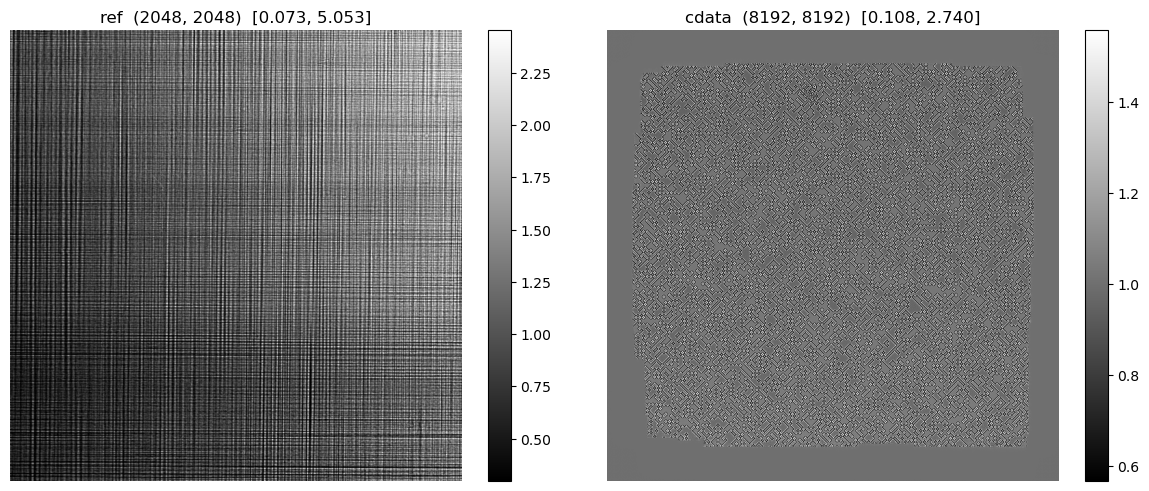

In [6]:
# Propagation operators at detector size (2048) — for ref
cl_prop      = Propagation(n,     nz,    1, 1, wavelength, voxelsize, [distance])
cl_prop_code = Propagation(n,     nz,    1, 1, wavelength, voxelsize, [distance_code])
# Propagation operators at full code size (8192) — for cdata
cl_prop_8192      = Propagation(ncode, ncode, 1, 1, wavelength, voxelsize, [distance])
cl_prop_code_8192 = Propagation(ncode, ncode, 1, 1, wavelength, voxelsize, [distance_code])

# Probe-only reference at detector (2048):  ref = |D( D_code(prb) )|^2
prb_gpu  = cp.array(prb)
prb_samp = cl_prop_code.D(prb_gpu, 0)
ref_gpu  = cl_prop.D(prb_samp, 0)
ref      = cp.abs(ref_gpu).real**2
ref      = ref.get()

# CA reference at full code size (8192, no probe):  cdata = |D( D_code(code) )|^2
print('Computing cdata at 8192...')
code_gpu       = cp.array(code)
code_samp_8192 = cl_prop_code_8192.D(code_gpu, 0)
cdata_gpu      = cl_prop_8192.D(code_samp_8192, 0)
cdata          = cp.abs(cdata_gpu).real**2   # (8192, 8192)
del code_gpu, code_samp_8192, cdata_gpu, code
cdata = cdata.get()

print(f'ref   : shape={ref.shape}  range=[{ref.min():.4f},{ref.max():.4f}]')
print(f'cdata : shape={cdata.shape}  range=[{cdata.min():.4f},{cdata.max():.4f}]')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im0 = axes[0].imshow(ref, cmap='gray',
    vmin=np.percentile(ref, 1), vmax=np.percentile(ref, 99))
axes[0].set_title(f'ref  {ref.shape}  [{ref.min():.3f}, {ref.max():.3f}]')
plt.colorbar(im0, ax=axes[0], fraction=0.046)
axes[0].axis('off')

im1 = axes[1].imshow(cdata, cmap='gray',
    vmin=np.percentile(cdata, 1), vmax=np.percentile(cdata, 99))
axes[1].set_title(f'cdata  {cdata.shape}  [{cdata.min():.3f}, {cdata.max():.3f}]')
plt.colorbar(im1, ax=axes[1], fraction=0.046)
axes[1].axis('off')

plt.tight_layout()
plt.show()


## Cross-correlation: find CA shifts

In [7]:
def phase_corr_gpu(a_gpu, b_gpu):
    """Cross-correlation (GPU). Returns (row_shift, col_shift) of b relative to a."""
    ip  = cp.fft.fft2(a_gpu) * cp.conj(cp.fft.fft2(b_gpu))
    cc  = cp.fft.fftshift(cp.fft.ifft2(ip).real)
    idx = cp.unravel_index(cp.argmax(cc), cc.shape)
    dy  = int(idx[0].get()) - cc.shape[0] // 2
    dx  = int(idx[1].get()) - cc.shape[1] // 2
    return np.array([dy, dx], dtype='float32')

shifts_code = np.zeros((ntheta, 2), dtype='float32')
cdata_gpu   = cp.array(cdata, dtype='float32')   # (8192, 8192)
pad         = (ncode - n) // 2                   # 3072 pixels on each side

print(f'Running xcorr for {ntheta} angles  '
      f'(cdata {ncode}x{ncode}, rdata padded from {nz}x{n})...')
with h5py.File(fname_in, 'r') as f:
    pdata_dset = f['/exchange/pdata']
    for k in range(ntheta):
        frame   = pdata_dset[k].astype('float32')
        rdata_k = frame / (ref + 1e-6)
        rdata_pad = cp.pad(cp.array(rdata_k),
                          ((pad, pad), (pad, pad)),
                          constant_values=1)
        shifts_code[k] = -phase_corr_gpu(cdata_gpu, rdata_pad)
        if k % 500 == 0:
            print(f'  k={k:5d}  CA shift = {shifts_code[k]}')

print('Done.')
print(f'shifts_code row: [{shifts_code[:,0].min():.1f}, {shifts_code[:,0].max():.1f}] px')
print(f'shifts_code col: [{shifts_code[:,1].min():.1f}, {shifts_code[:,1].max():.1f}] px')

Running xcorr for 7200 angles  (cdata 8192x8192, rdata padded from 2048x2048)...
  k=    0  CA shift = [ 78. 829.]
  k=  500  CA shift = [ 294. 1478.]
  k= 1000  CA shift = [-290. 1359.]
  k= 1500  CA shift = [ -887. -1007.]
  k= 2000  CA shift = [188. 833.]
  k= 2500  CA shift = [-560.  993.]
  k= 3000  CA shift = [-496. 1413.]
  k= 3500  CA shift = [653. 343.]
  k= 4000  CA shift = [217. 931.]
  k= 4500  CA shift = [533. 652.]
  k= 5000  CA shift = [-716. -156.]
  k= 5500  CA shift = [ 562. -875.]
  k= 6000  CA shift = [1015.  945.]
  k= 6500  CA shift = [549. 518.]
  k= 7000  CA shift = [435. 366.]
Done.
shifts_code row: [-1443.0, 1103.0] px
shifts_code col: [-1170.0, 2152.0] px


## Correction for the object shift

shifts_cor row after correction: [-18.87, 23.71] px


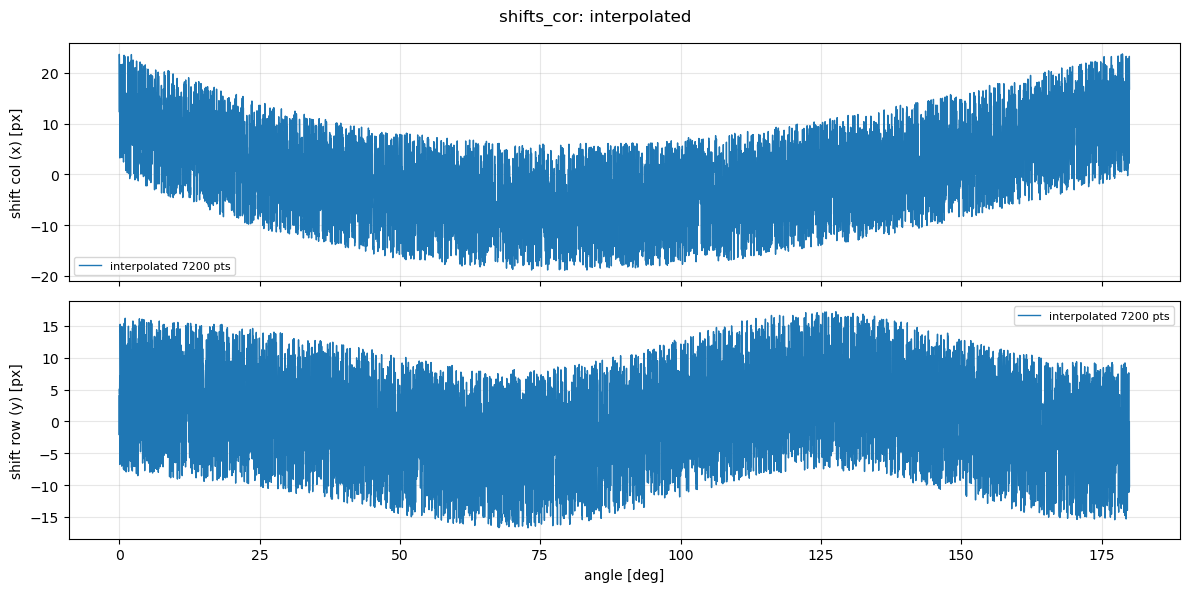

In [8]:
cc = np.loadtxt(CORRECTION_FILE)[:1800][:, ::-1].astype(np.float32)

x_old = np.linspace(np.array(theta_deg).min(), np.array(theta_deg).max(), 1800)
x_new = theta_deg  # shape (7200,), actual angles from h5

cc = np.stack([np.interp(x_new, x_old, cc[:, i]) for i in range(2)], axis=1).astype(np.float32)

shifts_cor = shifts.copy()
shifts_cor += cc

print(f'shifts_cor row after correction: [{shifts_cor[:,0].min():.2f}, {shifts_cor[:,0].max():.2f}] px')

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
labels = ['col (x)', 'row (y)']
for i, ax in enumerate(axes):
    ax.plot(theta_deg, shifts_cor[:, i], '-', lw=1, label='interpolated 7200 pts')
    ax.set_ylabel(f'shift {labels[i]} [px]')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
axes[1].set_xlabel('angle [deg]')
fig.suptitle('shifts_cor: interpolated')
plt.tight_layout()
plt.show()

## Visualisation

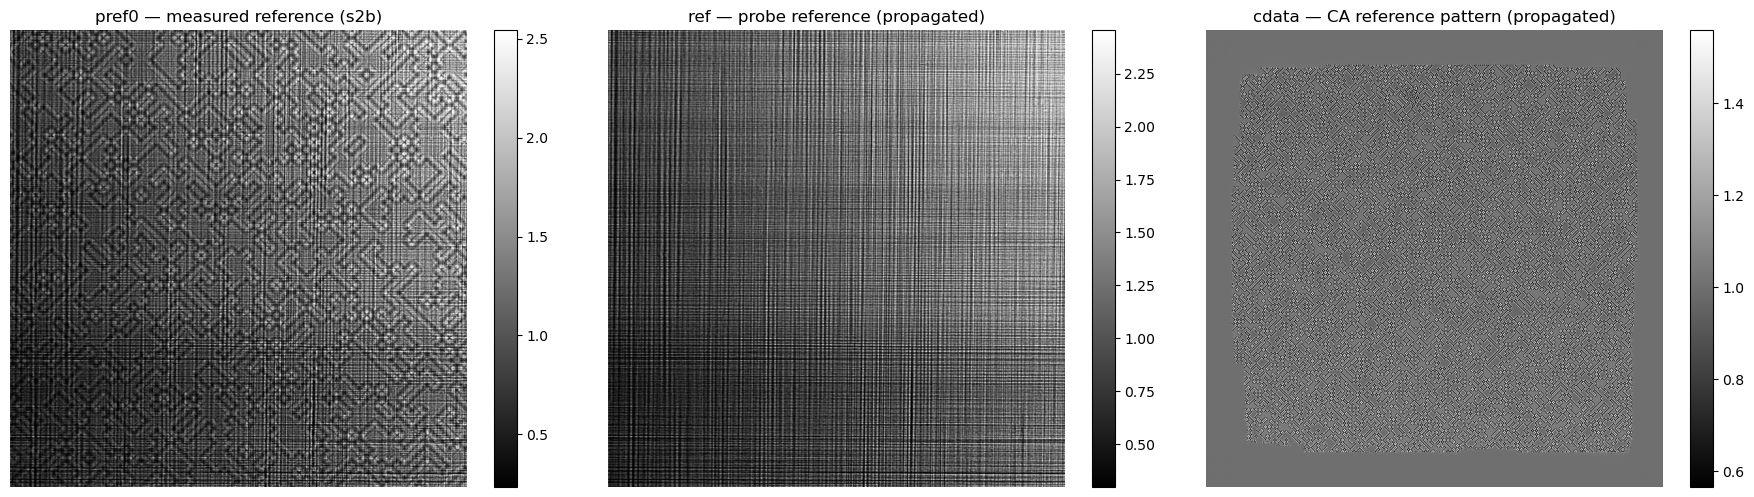

In [9]:
with h5py.File(fname_in, 'r') as f:
    pref0 = f['/exchange/pref0'][:].astype('float32')   # (nz, n)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im0 = axes[0].imshow(pref0, cmap='gray',
    vmin=np.percentile(pref0, 1), vmax=np.percentile(pref0, 99))
axes[0].set_title('pref0 — measured reference (s2b)')
plt.colorbar(im0, ax=axes[0], fraction=0.046)
axes[0].axis('off')

im1 = axes[1].imshow(ref, cmap='gray',
    vmin=np.percentile(ref, 1), vmax=np.percentile(ref, 99))
axes[1].set_title('ref — probe reference (propagated)')
plt.colorbar(im1, ax=axes[1], fraction=0.046)
axes[1].axis('off')

im2 = axes[2].imshow(cdata, cmap='gray',
    vmin=np.percentile(cdata, 1), vmax=np.percentile(cdata, 99))
axes[2].set_title('cdata — CA reference pattern (propagated)')
plt.colorbar(im2, ax=axes[2], fraction=0.046)
axes[2].axis('off')

plt.tight_layout()
plt.show()

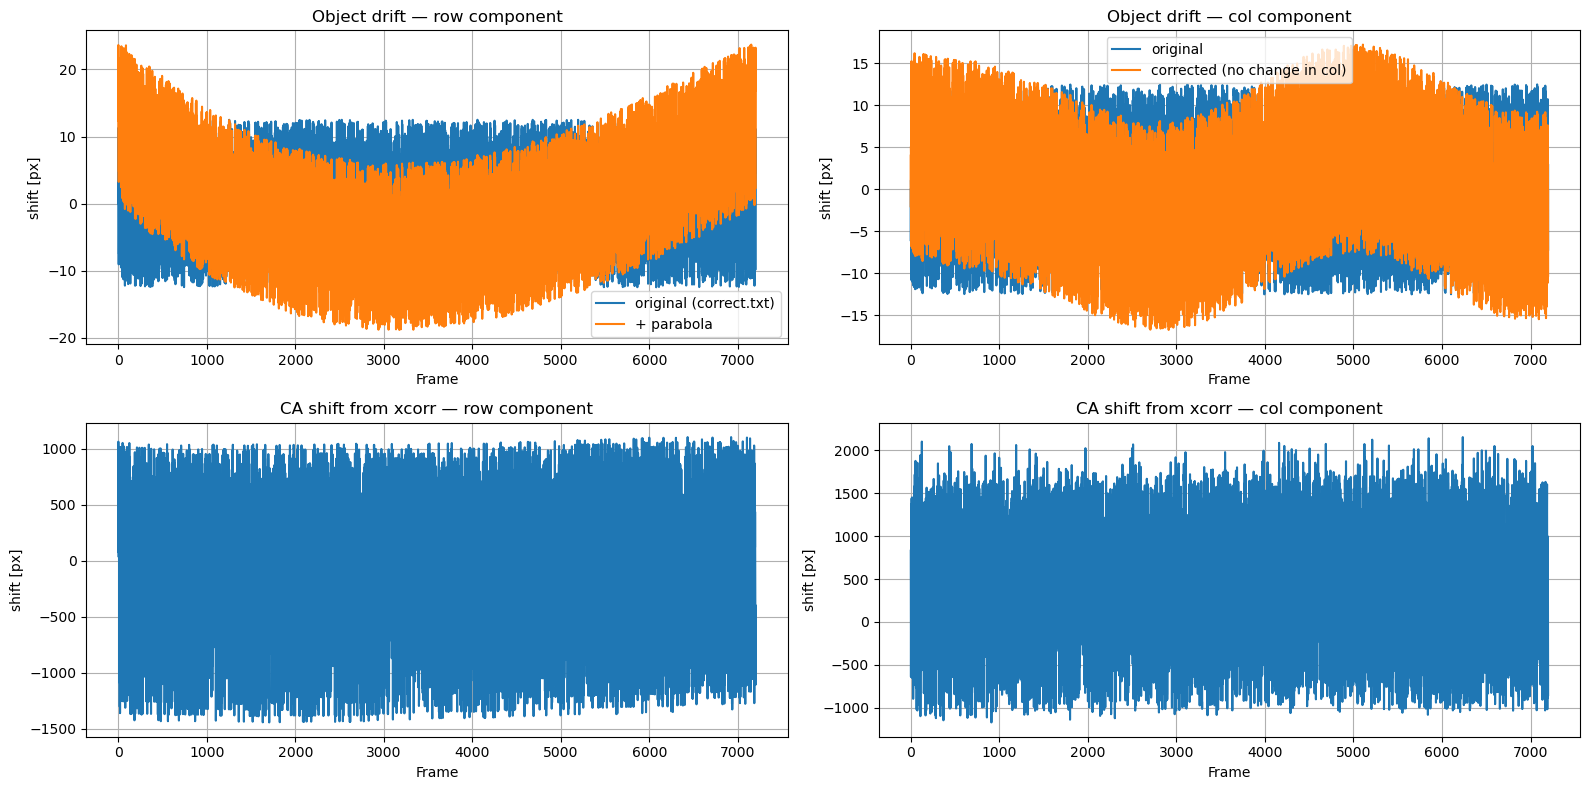

In [10]:
frame_idx = np.arange(ntheta)

fig, axes = plt.subplots(2, 2, figsize=(16, 8))

# Object shifts before and after parabolic correction
axes[0, 0].plot(frame_idx, shifts[:, 0],     label='original (correct.txt)')
axes[0, 0].plot(frame_idx, shifts_cor[:, 0], label=f'+ parabola')
axes[0, 0].set_title('Object drift — row component')
axes[0, 0].set_xlabel('Frame'); axes[0, 0].set_ylabel('shift [px]')
axes[0, 0].legend(); axes[0, 0].grid()

axes[0, 1].plot(frame_idx, shifts[:, 1],     label='original')
axes[0, 1].plot(frame_idx, shifts_cor[:, 1], label='corrected (no change in col)')
axes[0, 1].set_title('Object drift — col component')
axes[0, 1].set_xlabel('Frame'); axes[0, 1].set_ylabel('shift [px]')
axes[0, 1].legend(); axes[0, 1].grid()

# CA shifts from xcorr
axes[1, 0].plot(frame_idx, shifts_code[:, 0])
axes[1, 0].set_title('CA shift from xcorr — row component')
axes[1, 0].set_xlabel('Frame'); axes[1, 0].set_ylabel('shift [px]'); axes[1, 0].grid()

axes[1, 1].plot(frame_idx, shifts_code[:, 1])
axes[1, 1].set_title('CA shift from xcorr — col component')
axes[1, 1].set_xlabel('Frame'); axes[1, 1].set_ylabel('shift [px]'); axes[1, 1].grid()

plt.tight_layout()
plt.show()

## Save to `codedHT_007nm.h5`

In [11]:
with h5py.File(fname_in, 'a') as f:
    for key in ['/exchange/prb',
                '/exchange/shifts_cor', '/exchange/shifts_code']:
        if key in f:
            del f[key]

    f.create_dataset('/exchange/prb',         data=prb.astype('complex64'))       # (nz, n)
    f.create_dataset('/exchange/shifts_cor',  data=shifts_cor.astype('float32'))  # (ntheta, 2)
    f.create_dataset('/exchange/shifts_code', data=shifts_code.astype('float32')) # (ntheta, 2)

print(f'Appended to {fname_in}:')
print(f'  /exchange/prb         : {prb.shape}  complex64')
print(f'  /exchange/shifts_cor  : {shifts_cor.shape}  '
      f'row=[{shifts_cor[:,0].min():.2f},{shifts_cor[:,0].max():.2f}] px')
print(f'  /exchange/shifts_code : {shifts_code.shape}  '
      f'row=[{shifts_code[:,0].min():.1f},{shifts_code[:,0].max():.1f}] '
      f'col=[{shifts_code[:,1].min():.1f},{shifts_code[:,1].max():.1f}] px')
print('Note: code.npy is loaded directly by the reconstruction (no HDF5 copy).')

Appended to /data3/cekmekci/AtomiumS2_coded/ht/codedHT.h5:
  /exchange/prb         : (2048, 2048)  complex64
  /exchange/shifts_cor  : (7200, 2)  row=[-18.87,23.71] px
  /exchange/shifts_code : (7200, 2)  row=[-1443.0,1103.0] col=[-1170.0,2152.0] px
Note: code.npy is loaded directly by the reconstruction (no HDF5 copy).
